In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# simulation parameters
dt = 0.005
T = 20.0
t = np.arange(0, T, dt)
N = len(t)

# System: dε/dt = (f_y - f_u c_P) ε - f_u c_I ∫ε dt + η(t)
# linearised around setpoint with f_y < 0 (stable plant), f_u > 0
f_y = -0.2          # intrinsic relaxation (weak)
f_u = 1.0           # actuator gain
c_P = 2.0           # proportional gain
c_I = 1.5           # integral gain (used only for PI)
alpha = f_y - f_u * c_P   # effective P-loop rate (should be negative)

# Disturbance 1: short pulse
t_pulse = 4.0          # pulse centre
pulse_width = 1.8      # full-width of the pulse
pulse_height = 1.0
eta_pulse = pulse_height * np.exp(-0.5 * ((t - t_pulse) / (pulse_width / 4))**2)

# Disturbance 2: sigmoid step
t_step = 6.0
step_height = 1.0
steepness = 3.0
eta_step = step_height / (1.0 + np.exp(-steepness * (t - t_step)))

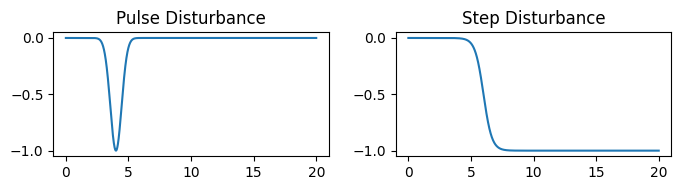

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(7, 2))
axes[0].plot(t, -eta_pulse)
axes[0].set_title('Pulse Disturbance')
axes[1].plot(t, -eta_step)
axes[1].set_title('Step Disturbance')
plt.tight_layout()

In [8]:
# define simulators that take in the disturbance and return the error and control signal
def simulate_P(eta):
    """P-only: dε/dt = α ε + η,  u = c_P ε"""
    eps = np.zeros(N)
    u = np.zeros(N)
    for i in range(1, N):
        eps[i] = eps[i - 1] + dt * (alpha * eps[i - 1] + eta[i - 1])
        u[i] = c_P * eps[i]
    return eps, u

def simulate_PI(eta):
    """PI: second-order  d²ε/dt² = α dε/dt - f_u c_I ε + dη/dt
    rewritten as two first-order ODEs:
        dε/dt  = v
        dv/dt  = α v - f_u c_I ε + dη/dt
    u = c_P ε + c_I ∫ε dt
    """
    eps = np.zeros(N)
    v = np.zeros(N)
    u = np.zeros(N)
    int_eps = 0.0
    for i in range(1, N):
        deta = (eta[i] - eta[i - 1]) / dt
        v[i] = v[i - 1] + dt * (alpha * v[i - 1] - f_u * c_I * eps[i - 1] + deta)
        eps[i] = eps[i - 1] + dt * v[i - 1]
        int_eps += eps[i] * dt
        u[i] = c_P * eps[i] + c_I * int_eps
    return eps, u

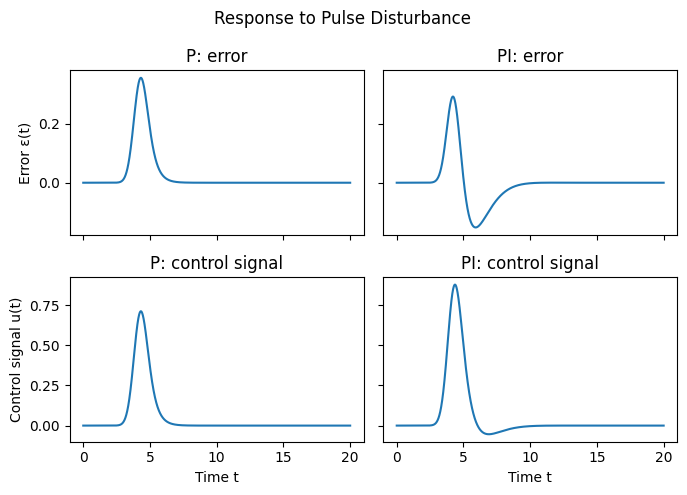

In [17]:
# Run and plot pulsed simulations
eps_P_pulse, u_P_pulse = simulate_P(eta_pulse)
eps_PI_pulse, u_PI_pulse = simulate_PI(eta_pulse)

fig, axes = plt.subplots(2, 2, figsize=(7, 5), sharex=True, sharey = 'row')
axes[0, 0].plot(t, eps_P_pulse, label='P-only')
axes[0, 0].set_title('P: error')
axes[0, 1].plot(t, eps_PI_pulse, label='PI')
axes[0, 1].set_title('PI: error')
axes[0, 0].set_ylabel('Error ε(t)')
axes[1, 0].set_ylabel('Control signal u(t)')
axes[1, 0].set_xlabel('Time t')
axes[1, 1].set_xlabel('Time t')

axes[1, 0].plot(t, u_P_pulse, label='P-only')
axes[1, 0].set_title('P: control signal')
axes[1, 1].plot(t, u_PI_pulse, label='PI')
axes[1, 1].set_title('PI: control signal')
plt.suptitle('Response to Pulse Disturbance')
plt.tight_layout()
plt.savefig("demo_pulse.png", dpi=300)

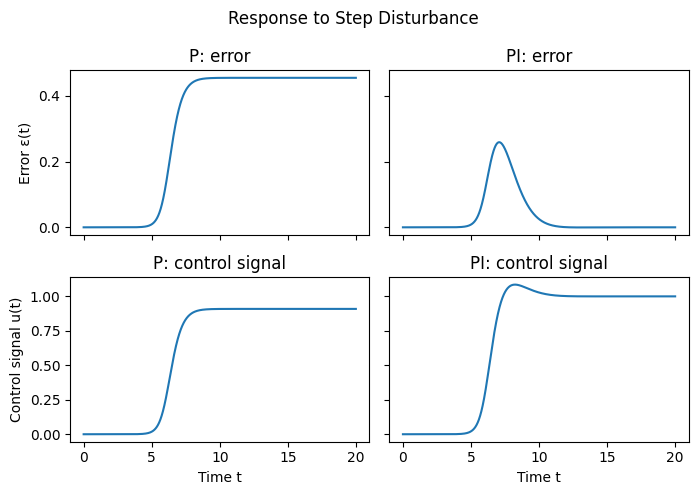

In [18]:
# Run and plot step simulations
eps_P_step, u_P_step = simulate_P(eta_step)
eps_PI_step, u_PI_step = simulate_PI(eta_step)

fig, axes = plt.subplots(2, 2, figsize=(7, 5), sharex=True, sharey = 'row')
axes[0, 0].plot(t, eps_P_step, label='P-only')
axes[0, 0].set_title('P: error')
axes[0, 1].plot(t, eps_PI_step, label='PI')
axes[0, 1].set_title('PI: error')
axes[0, 0].set_ylabel('Error ε(t)')
axes[1, 0].set_ylabel('Control signal u(t)')
axes[1, 0].set_xlabel('Time t')
axes[1, 1].set_xlabel('Time t')
axes[1, 0].plot(t, u_P_step, label='P-only')
axes[1, 0].set_title('P: control signal')
axes[1, 1].plot(t, u_PI_step, label='PI')
axes[1, 1].set_title('PI: control signal')
plt.suptitle('Response to Step Disturbance')
plt.tight_layout()
plt.savefig("demo_step.png", dpi=300)